[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/05_benchmark_scaffold_hopping.ipynb)

# 05 · Benchmark 2 — Scaffold Hopping

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~50 min*

Virtual screening that only finds close analogues of your query is of limited value — you often *already own* the analogues. The prize is **scaffold hopping**: finding actives built on a **different chemical core**. Exact circular fingerprints (ECFP), which key on precise atom environments, are known to struggle here. We test whether feature-based and topological fingerprints bridge scaffolds better, with real numbers on DUD-E EGFR.

**Learning objectives.** By the end of this notebook you will be able to:

- define scaffold hopping with Bemis–Murcko generic scaffolds
- re-run the screen counting only recovery of **different-scaffold** actives
- measure **cross-scaffold similarity retention** per fingerprint
- explain why FCFP / atom-pair / key fingerprints hop scaffolds better than exact ECFP

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


In [2]:
import numpy as np, pandas as pd
act = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/dude_egfr_actives.csv"))
dec = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/dude_egfr_decoys.csv"))
print(f"DUD-E EGFR benchmark: {len(act)} actives, {len(dec)} property-matched decoys")
# the exact query set used by scripts/run_benchmarks.py (so live numbers match the JSON)
query_idx = sorted(np.random.default_rng(7).choice(len(act), size=25, replace=False).tolist())
print("query actives (seed 7):", len(query_idx))

DUD-E EGFR benchmark: 542 actives, 3000 property-matched decoys
query actives (seed 7): 25


## 1. Generic scaffolds

The **Bemis–Murcko generic scaffold** strips side chains and then flattens every atom to carbon and every bond to single — leaving just the ring/linker topology. Two molecules with the same generic scaffold share a core; different generic scaffolds = a scaffold hop.

In [3]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
def generic_scaffold(mol):
    try:
        return Chem.MolToSmiles(MurckoScaffold.MakeScaffoldGeneric(MurckoScaffold.GetScaffoldForMol(mol)))
    except Exception:
        return None
act_scaf = [generic_scaffold(m) for m in act["mol"]]
n_scaf = len(set(s for s in act_scaf if s))
print(f"{n_scaf} distinct generic scaffolds among {len(act)} actives")

288 distinct generic scaffolds among 542 actives


## 2. Cross-scaffold screen — computed live

Same single-query screen as Notebook 04, but now we **remove same-scaffold actives** from the hit set, so only recovery of a *different* core counts. Compare BEDROC here with the plain VS BEDROC from Notebook 04.

In [4]:
act_fps = {n: fsg.make_fps(n, list(act["mol"])) for n in fsg.FP_NAMES}
dec_fps = {n: fsg.make_fps(n, list(dec["mol"])) for n in fsg.FP_NAMES}
rows = []
for name in fsg.FP_NAMES:
    vs  = fsg.ligand_based_screen(act_fps[name], dec_fps[name], "tanimoto", query_idx)
    hop = fsg.ligand_based_screen(act_fps[name], dec_fps[name], "tanimoto", query_idx,
                                  scaffolds=act_scaf, scaffold_hop=True)
    rows.append((name, vs["BEDROC"], hop["BEDROC"], round(hop["BEDROC"]-vs["BEDROC"], 3)))
pd.DataFrame(rows, columns=["fingerprint","VS BEDROC","scaffold-hop BEDROC","delta"]).sort_values("scaffold-hop BEDROC", ascending=False).reset_index(drop=True)

,fingerprint,VS BEDROC,scaffold-hop BEDROC,delta
0,Torsion,0.851,0.850,-0.001
1,ECFP4-2048,0.849,0.847,-0.002
2,ECFP6-2048,0.832,0.830,-0.002
3,ECFP4-counts,0.830,0.829,-0.001
4,ECFP4-1024,0.829,0.828,-0.001
5,FCFP4-2048,0.821,0.819,-0.002
6,Avalon,0.698,0.694,-0.004
7,AtomPair,0.680,0.675,-0.005
8,RDKit,0.587,0.583,-0.004
9,MACCS,0.532,0.526,-0.006


On DUD-E EGFR the ranked recovery barely changes when same-scaffold hits are removed — the actives are analogue-rich, so removing one same-scaffold neighbour leaves many others. That retrieval view is **not sensitive enough** to show scaffold hopping. We need a sharper probe.

## 3. Cross-scaffold similarity retention

The sensitive question is: **how much active–active similarity survives when the two actives sit on different scaffolds?** We compute, per fingerprint, the mean similarity for same-scaffold pairs vs different-scaffold pairs. The ratio `cross / same` is a direct scaffold-hopping score: higher = the fingerprint keeps seeing two actives as similar even across cores.

In [5]:
import json, os
import pandas as pd
DOCS_DIR = os.path.join(ROOT, "docs")
RESULTS = json.load(open(os.path.join(DOCS_DIR, "benchmark_results.json")))
print("Loaded committed benchmark results from docs/benchmark_results.json")

Loaded committed benchmark results from docs/benchmark_results.json


In [6]:
ret = RESULTS["benchmark2_scaffold_hopping"]["retention"]
ret_df = pd.DataFrame([{"fingerprint": k, **v} for k, v in ret.items()]).sort_values("retention_ratio", ascending=False)
ret_df.reset_index(drop=True)

,fingerprint,same_scaffold_mean_sim,cross_scaffold_mean_sim,retention_ratio
0,MACCS,0.731,0.496,0.679
1,RDKit,0.605,0.397,0.658
2,AtomPair,0.608,0.347,0.570
3,ECFP4-counts,0.524,0.261,0.498
4,Torsion,0.533,0.253,0.474
5,Avalon,0.624,0.296,0.474
6,FCFP4-2048,0.524,0.247,0.473
7,ECFP4-1024,0.476,0.201,0.421
8,ECFP4-2048,0.471,0.192,0.409
9,ECFP6-2048,0.412,0.150,0.363


Now the textbook effect is clear. **Exact ECFP (especially ECFP6) retains the *least* cross-scaffold similarity** — it is the worst scaffold hopper. **Feature-based FCFP beats exact ECFP**, and topological/key fingerprints (RDKit paths, atom pairs, MACCS) retain the most similarity across scaffolds.

The catch: that same 'blurriness' is why MACCS and RDKit **lose** the virtual-screening benchmark (Notebook 04) — they call too many *different* molecules similar. Scaffold hopping and screening specificity pull in opposite directions.

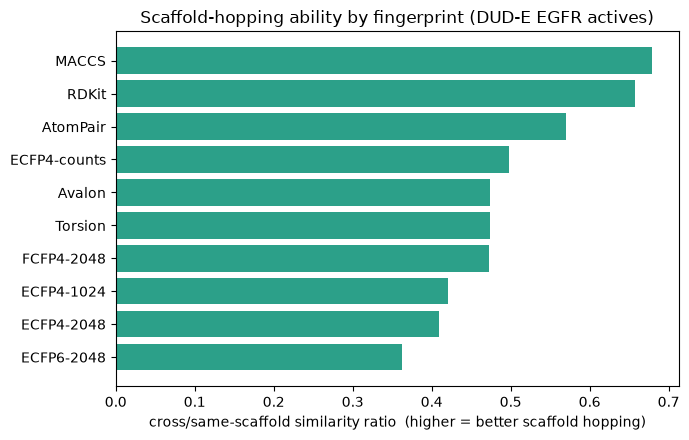

In [7]:
import matplotlib.pyplot as plt
d = ret_df.sort_values("retention_ratio")
plt.figure(figsize=(7,4.5))
plt.barh(d["fingerprint"], d["retention_ratio"], color="#2ca089")
plt.xlabel("cross/same-scaffold similarity ratio  (higher = better scaffold hopping)")
plt.title("Scaffold-hopping ability by fingerprint (DUD-E EGFR actives)")
plt.tight_layout(); plt.show()

## Summary

- **Exact ECFP is the weakest scaffold hopper**; ECFP6 (bigger radius, more specific) is worst.
- **FCFP (feature-based) > ECFP**, and RDKit-path / atom-pair / MACCS retain the most cross-scaffold similarity.
- That same tolerance makes them *worse* at focused virtual screening — pick for the task: **specificity (ECFP) for analogue screening, tolerance (FCFP/atom-pair) for scaffold hopping.**

Next: do similar fingerprints actually imply similar *activity*? Activity cliffs say "not always."

### ✏️ Exercise 1

Which fingerprint has the largest gap between same- and cross-scaffold mean similarity (i.e. drops off most across scaffolds)?

<details>
<summary><b>Show solution</b></summary>

```python
ret_df["gap"] = ret_df["same_scaffold_mean_sim"] - ret_df["cross_scaffold_mean_sim"]
print(ret_df.sort_values("gap", ascending=False)[["fingerprint","gap"]].head())
```

</details>

### ✏️ Exercise 2

Compute the retention ratio for ECFP4 vs FCFP4 directly from the retention table and confirm FCFP > ECFP.

<details>
<summary><b>Show solution</b></summary>

```python
for n in ["ECFP4-2048","FCFP4-2048"]:
    print(n, ret[n]["retention_ratio"])
```

</details>